In [1]:
import hashlib
import os
import platform
import uuid

# 修改为自己的学号
STUDENT_ID = 20244080210  # 改成数字，不要加引号

CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV")
print(f"[Conda 环境] {CONDA_ENV}")

MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号] {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID] {RUN_ID}")

[Conda 环境] exp01
[学号] 20244080210
[机器指纹] 90cf8d31534ddeec
[RUN_ID] 20244080210-90cf8d31534ddeec


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# 围绕半圆定律

### 1. 编写 wigner_density(x)

In [3]:
def wigner_density(x):
    # 使用 np.where 来应对数组操作（如果传入的是标量也能正常工作）
    return np.where(np.abs(x) <= 2, (1 / (2 * np.pi)) * np.sqrt(4 - x**2), 0.0)

# 测试
print(wigner_density(1.0)) # 应该输出约 0.275

0.27566444771089604


### 2. 编写 generate_wigner(n)

In [4]:
def generate_wigner(n):
    if not isinstance(n, (int, np.integer)) or n <= 0:
        raise ValueError("n 必须是正整数")
    # 生成标准正态分布矩阵，并缩放至方差 1/n
    Z = np.random.randn(n, n) / np.sqrt(n)
    # 构造对称矩阵（保留上三角，下三角由转置得到）
    Z_sym = np.triu(Z) + np.triu(Z, 1).T
    return Z_sym

### 3. 编写 get_spectrum(matrix)

In [5]:
def get_spectrum(matrix):
    # 因为是实对称矩阵，用 eigvalsh 计算特征值更快且必定返回实数
    eigenvalues = np.linalg.eigvalsh(matrix)
    return np.sort(eigenvalues)

### 4. 画图并说明

C:\Users\xjq\AppData\Local\Temp\ipykernel_25424\1778055015.py:6: RuntimeWarning: invalid value encountered in sqrt
  return np.where(np.abs(x) <= 2, (1 / (2 * np.pi)) * np.sqrt(4 - x**2), 0.0)
C:\Users\xjq\AppData\Local\Temp\ipykernel_25424\1778055015.py:39: UserWarning: Glyph 29305 (\N{CJK UNIFIED IDEOGRAPH-7279}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\xjq\AppData\Local\Temp\ipykernel_25424\1778055015.py:39: UserWarning: Glyph 24449 (\N{CJK UNIFIED IDEOGRAPH-5F81}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\xjq\AppData\Local\Temp\ipykernel_25424\1778055015.py:39: UserWarning: Glyph 20540 (\N{CJK UNIFIED IDEOGRAPH-503C}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\xjq\AppData\Local\Temp\ipykernel_25424\1778055015.py:39: UserWarning: Glyph 20998 (\N{CJK UNIFIED IDEOGRAPH-5206}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\xjq\AppData\Local\Temp\ipykernel_25424\1778055015.py:39: UserWarning: Glyph 24067 

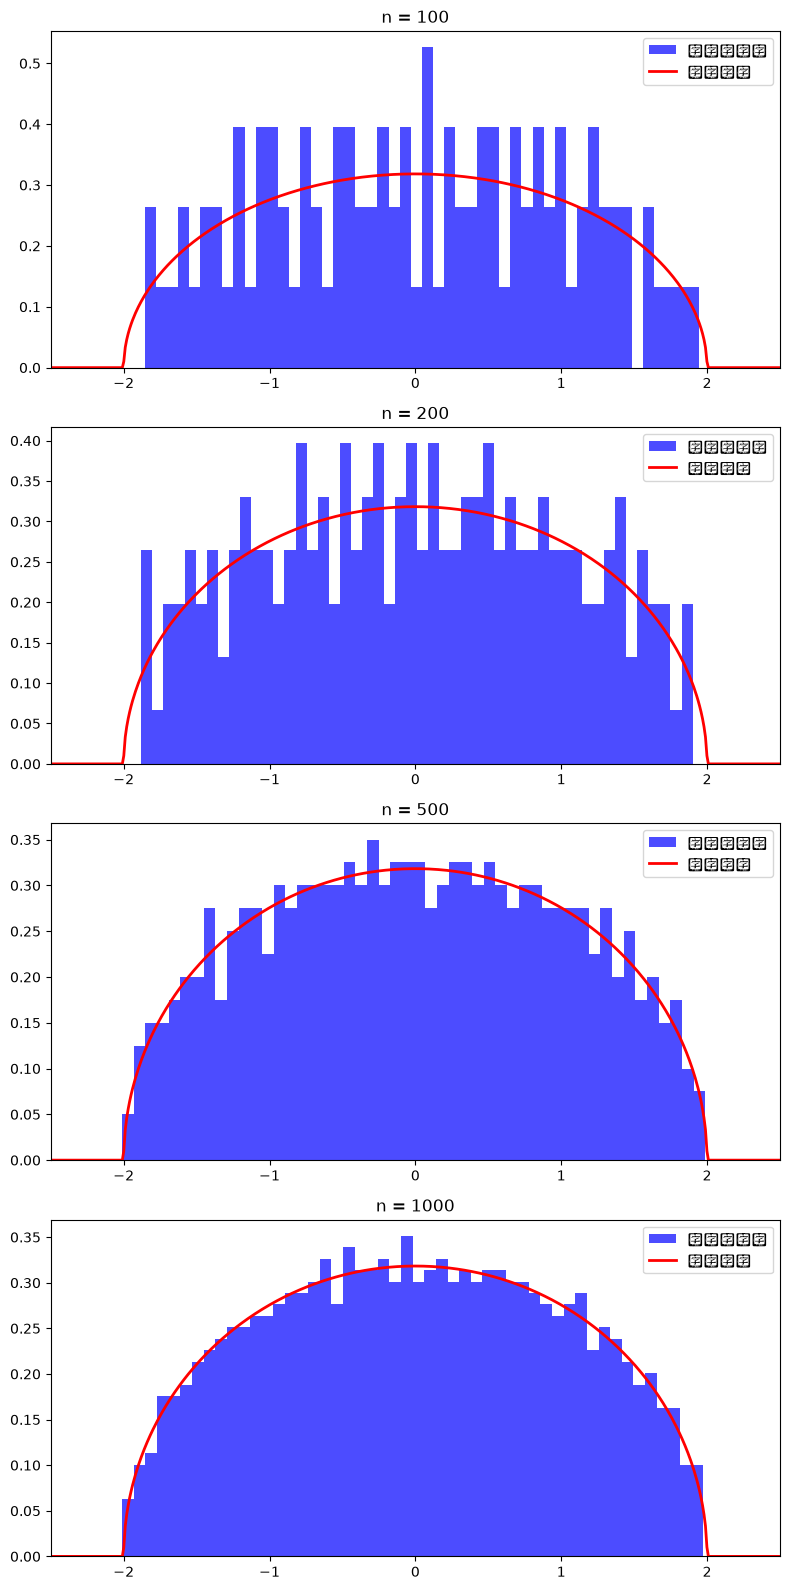

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# ================= 1. 定义三个函数 =================
def wigner_density(x):
    return np.where(np.abs(x) <= 2, (1 / (2 * np.pi)) * np.sqrt(4 - x**2), 0.0)

def generate_wigner(n):
    if not isinstance(n, (int, np.integer)) or n <= 0:
        raise ValueError("n 必须是正整数")
    Z = np.random.randn(n, n) / np.sqrt(n)
    Z_sym = np.triu(Z) + np.triu(Z, 1).T
    return Z_sym

def get_spectrum(matrix):
    eigenvalues = np.linalg.eigvalsh(matrix)
    return np.sort(eigenvalues)

# ================= 2. 开始画图 =================
n_values = [100, 200, 500, 1000]
fig, axes = plt.subplots(4, 1, figsize=(8, 16))

x_range = np.linspace(-2.5, 2.5, 500)
y_density = wigner_density(x_range)

for ax, n in zip(axes, n_values):
    W = generate_wigner(n)
    eigvals = get_spectrum(W)
    
    # 绘制标准化直方图
    ax.hist(eigvals, bins=50, density=True, color='blue', alpha=0.7, label='特征值分布')
    # 绘制半圆曲线
    ax.plot(x_range, y_density, color='red', linewidth=2, label='半圆密度')
    
    ax.set_title(f"n = {n}")
    ax.set_xlim(-2.5, 2.5)
    ax.legend()

plt.tight_layout()
plt.show()

从图中可以看出，当 n = 100 时，特征值分布的边缘已经有收敛趋势，但仍有明显波动；当 n 大约达到 500 甚至 1000 时，直方图与红色的半圆密度曲线拟合得非常好。

# Conway 的生命游戏

### 1. 编写 is_valid_board(board)

In [6]:
def is_valid_board(board):
    # 必须是二维数组，且所有元素只能是 0 或 1
    return isinstance(board, np.ndarray) and board.ndim == 2 and np.all(np.isin(board, [0, 1]))

### 2. 编写 gol_step(board)

In [7]:
def gol_step(board):
    if not is_valid_board(board):
        raise ValueError("输入必须是一个有效的生命游戏棋盘（二维 ndarray，元素为 0 或 1）")
    
    # 使用 np.roll 实现环绕边界的邻居计数
    neighbors = np.zeros_like(board)
    for i in [-1, 0, 1]:
        for j in [-1, 0, 1]:
            if i == 0 and j == 0:
                continue
            neighbors += np.roll(np.roll(board, i, axis=0), j, axis=1)
            
    # 规则应用
    new_board = np.zeros_like(board)
    # 活细胞存活：有 2 或 3 个活邻居
    new_board[(board == 1) & ((neighbors == 2) | (neighbors == 3))] = 1
    # 死细胞复活：恰好 3 个活邻居
    new_board[(board == 0) & (neighbors == 3)] = 1
    
    return new_board

### 3. 编写 draw_gol_board(board)

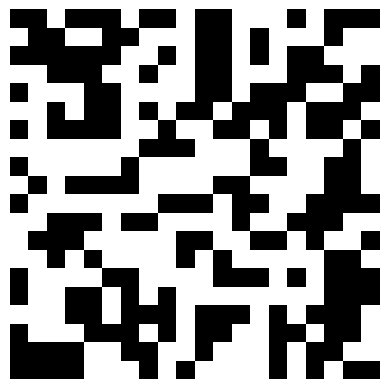

In [8]:
def draw_gol_board(board):
    plt.imshow(board, cmap='binary', interpolation='nearest')
    plt.xticks([]) # 隐藏 x 轴刻度
    plt.yticks([]) # 隐藏 y 轴刻度
    plt.axis('off') # 关闭坐标轴
    plt.show()
    
# 简单测试一下（你可以自己随便造一个棋盘跑一下）
test_board = np.random.choice([0, 1], size=(20, 20))
draw_gol_board(test_board)

# 使用 pandas DataFrame

### 1. 读取数据并回答

In [4]:
import pandas as pd

# 读取老师给的新表
df = pd.read_csv('Iris.csv')

print("--- 1. 数据概况 ---")
print("数据点个数:", df.shape[0])
print("\n每列的数据类型:\n", df.dtypes)
print("\n列名是什么:", df.columns.tolist())
print("\n数据中有多少种花卉:", df['Species'].unique())

--- 1. 数据概况 ---
数据点个数: 150

每列的数据类型:
 Id                 int64
SepalLengthCm    float64
SepalWidthCm     float64
PetalLengthCm    float64
PetalWidthCm     float64
Species              str
dtype: object

列名是什么: ['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm', 'Species']

数据中有多少种花卉: <StringArray>
['Iris-setosa', 'Iris-versicolor', 'Iris-virginica']
Length: 3, dtype: str


### 2. 修改错误数据

In [5]:
print("--- 2. 修改错误数据 ---")

# 修改第 35 行（索引 34）
df.loc[34, 'SepalLengthCm'] = 4.9
df.loc[34, 'SepalWidthCm'] = 3.1
df.loc[34, 'PetalLengthCm'] = 1.5
df.loc[34, 'PetalWidthCm'] = 0.2
df.loc[34, 'Species'] = 'Iris-setosa' # 保持原表格式

# 修改第 38 行（索引 37）
df.loc[37, 'SepalLengthCm'] = 4.9
df.loc[37, 'SepalWidthCm'] = 3.6
df.loc[37, 'PetalLengthCm'] = 1.4
df.loc[37, 'PetalWidthCm'] = 0.1
df.loc[37, 'Species'] = 'Iris-setosa'

print("修改后的索引 34 行:\n", df.loc[34])
print("\n修改后的索引 37 行:\n", df.loc[37])

--- 2. 修改错误数据 ---
修改后的索引 34 行:
 Id                        35
SepalLengthCm            4.9
SepalWidthCm             3.1
PetalLengthCm            1.5
PetalWidthCm             0.2
Species          Iris-setosa
Name: 34, dtype: object

修改后的索引 37 行:
 Id                        38
SepalLengthCm            4.9
SepalWidthCm             3.6
PetalLengthCm            1.4
PetalWidthCm             0.1
Species          Iris-setosa
Name: 37, dtype: object


### 3.添加新特征

In [6]:
print("--- 3. 添加新特征 ---")

# 计算比例并新增列
df['Petal.Ratio'] = df['PetalLengthCm'] / df['PetalWidthCm']
df['Sepal.Ratio'] = df['SepalLengthCm'] / df['SepalWidthCm']

# 展示一下新加的两列
print(df[['Petal.Ratio', 'Sepal.Ratio']].head())

--- 3. 添加新特征 ---
   Petal.Ratio  Sepal.Ratio
0          7.0     1.457143
1          7.0     1.633333
2          6.5     1.468750
3          7.5     1.483871
4          7.0     1.388889


### 4.保存文件

In [7]:
print("--- 4. 保存文件 ---")

# 保存文件，不保存行索引（默认的 0,1,2...）
df.to_csv('iris_corrected.csv', index=False)
print("文件已成功保存为 iris_corrected.csv！请去左侧文件夹确认。")

--- 4. 保存文件 ---
文件已成功保存为 iris_corrected.csv！请去左侧文件夹确认。


### 5.按花卉种类分组计算

In [8]:
print("--- 5. 分组统计 ---")

# 按 Species 分组，对两个比例列计算平均值、中位数、最小值、最大值和标准差
grouped_stats = df.groupby('Species')[['Petal.Ratio', 'Sepal.Ratio']].agg(
    ['mean', 'median', 'min', 'max', 'std']
)

print(grouped_stats)

--- 5. 分组统计 ---
                Petal.Ratio                                     Sepal.Ratio  \
                       mean    median       min   max       std        mean   
Species                                                                       
Iris-setosa        6.908000  7.000000  2.666667  15.0  2.854545    1.470188   
Iris-versicolor    3.242837  3.240385  2.666667   4.1  0.312456    2.160402   
Iris-virginica     2.780662  2.666667  2.125000   4.0  0.407367    2.230453   

                                                         
                   median       min       max       std  
Species                                                  
Iris-setosa      1.463063  1.268293  1.956522  0.118750  
Iris-versicolor  2.161290  1.764706  2.818182  0.228658  
Iris-virginica   2.169540  1.823529  2.961538  0.246992  
